<a href="https://colab.research.google.com/github/ummubdryh/PM-Turi4-Clustering/blob/main/pm_turi4_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LANGKAH PRAKTIKUM

Langkah 1- Menyiapkan data & scaling (wajib).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

df = pd.DataFrame({
    'usia': [19, 22, 25, 28, 30, 35, 40, 45, 50, 55],
    'pendapatan': [2000000, 2500000, 3000000, 3500000,
                   4000000, 4500000, 5000000, 6000000,
                   7000000, 8000000],
    'skor_belanja': [80, 75, 90, 65, 70, 50, 45, 35, 30, 20]
})

print(df)
X_scaled = StandardScaler().fit_transform(df)

   usia  pendapatan  skor_belanja
0    19     2000000            80
1    22     2500000            75
2    25     3000000            90
3    28     3500000            65
4    30     4000000            70
5    35     4500000            50
6    40     5000000            45
7    45     6000000            35
8    50     7000000            30
9    55     8000000            20


Langkah 2-Metode Elbow menentukan K

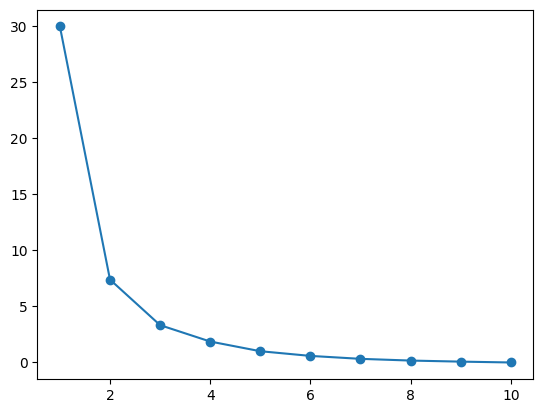

In [ ]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o'); plt.show()


Langkah 3-menjalankan K-Means (K=3)

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())


cluster
0    5
2    3
1    2
Name: count, dtype: int64


Langkah 4-Evaluasi silhouette score

In [ ]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))


0.4971792185340126


Langkah 5-Interpretasi : Profil rata-rata tiap cluster

In [ ]:
profil = df.groupby('cluster')[['usia','pendapatan','skor_belanja']].mean().round(1)
print(profil)   # beri nama tiap cluster berdasarkan profil


         usia  pendapatan  skor_belanja
cluster                                
0        24.8   3000000.0          76.0
1        52.5   7500000.0          25.0
2        40.0   5166666.7          43.3


#D.LATIHAN MANDIRI

6. Jalankan K-Means K=5; bandingkan silhouette score dengan K=3.

Jalankan K-Means K=5;

In [ ]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())

cluster
2    3
0    2
3    2
1    2
4    1
Name: count, dtype: int64


bandingkan silhouette score dengan K=3.

In [ ]:
from sklearn.metrics import silhouette_score

# K-Means K=3
kmeans3 = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster3 = kmeans3.fit_predict(X_scaled)
score3 = silhouette_score(X_scaled, cluster3)

# K-Means K=5
kmeans5 = KMeans(n_clusters=5, random_state=42, n_init=10)
cluster5 = kmeans5.fit_predict(X_scaled)
score5 = silhouette_score(X_scaled, cluster5)

print("Silhouette Score K=3:", score3)
print("Silhouette Score K=5:", score5)

Silhouette Score K=3: 0.4971792185340126
Silhouette Score K=5: 0.3997775805696806


7. Jalankan K-Means tanpa scaling (K=3), bandingkan silhouette-nya. Apa kesimpulannya?

In [ ]:
X = df[['usia', 'pendapatan', 'skor_belanja']]

kmeans_no_scaling = KMeans(
    n_clusters=3, random_state=42, n_init=10
)

cluster_no_scaling = kmeans_no_scaling.fit_predict(X)
score_no_scaling = silhouette_score(X, cluster_no_scaling)

print("Dengan scaling:", score3)
print("Tanpa scaling:", score_no_scaling)

Dengan scaling: 0.4971792185340126
Tanpa scaling: 0.4882395382419701


8. Buat scatter plot cluster pada fitur usia (x) vs skor_belanja (y).


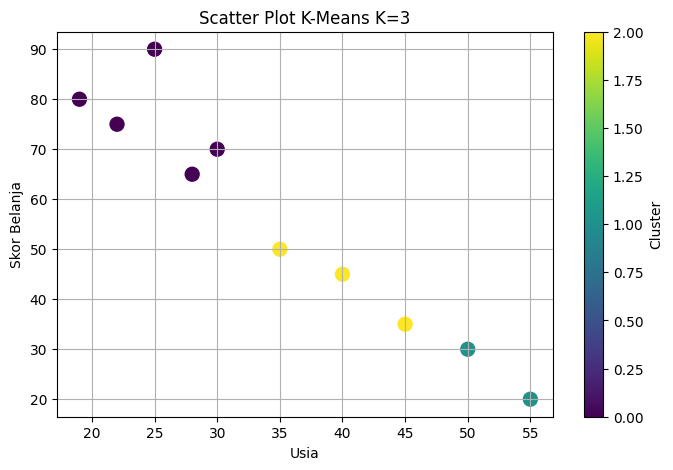

In [ ]:
df['cluster'] = cluster3

plt.figure(figsize=(8, 5))

plt.scatter(
    df['usia'],
    df['skor_belanja'],
    c=df['cluster'],
    cmap='viridis',
    s=100
)

plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.title('Scatter Plot K-Means K=3')
plt.colorbar(label='Cluster')
plt.grid(True)
plt.show()

# E.REFLEKSI

9. Bagaimana K-Means menemukan kelompok tanpa label?


K-Means bisa mengelompokkan data meskipun belum ada labelnya karena algoritma ini melihat kemiripan dari setiap data. Data yang memiliki karakteristik hampir sama akan dimasukkan ke kelompok yang sama berdasarkan jaraknya. Proses ini dilakukan berulang sampai pembagian kelompoknya sudah stabil.

10. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?


Pada grafik Elbow, K=3 dipilih karena penurunan nilai inertia mulai melambat setelah jumlah cluster mencapai tiga. Artinya, menambah jumlah cluster lagi tidak terlalu banyak mengurangi inertia. Jadi, tiga cluster bisa menjadi pilihan yang cukup baik untuk mengelompokkan data tersebut, jika memang bentuk grafiknya menunjukkan siku di titik itu.

11. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?

Scaling diperlukan karena nilai setiap fitur berbeda-beda. Pada data ini, pendapatan memiliki nilai sampai jutaan, sedangkan usia dan skor belanja nilainya jauh lebih kecil. Kalau tidak menggunakan scaling, pengelompokan bisa lebih banyak dipengaruhi oleh pendapatan. Dengan scaling, perbedaan skala tersebut bisa dikurangi sehingga setiap fitur lebih seimbang dalam proses pengelompokan.